# Laboratório 6 — Quando a reta precisa de freio, e quando o alvo é um sim/não

**Aprendizagem de Máquina Supervisionada — 2026.2 · Aula 6 (22/10)**
Dados reais: **RAIS 2025, vínculos formais da Paraíba**, base analítica salva no laboratório 5 (mesma partição treino/teste). Partes A1–A5 e B1 usam dados **simulados ou de brinquedo**, declarados como tais.

**Duas perguntas.**
1. *Regressão.* O Remunerômetro da aula 5 usava só escolaridade. Se colocarmos ocupação, setor, município, porte e natureza do empregador, o número de coeficientes passa de 2 para centenas. Com poucos dados de treino, o MQO deixa de generalizar. **Ridge, lasso e elastic net** resolvem isso mudando o que se minimiza.
2. *Classificação.* E se a pergunta for binária, "este vínculo paga mais de 2 salários mínimos?" A saída passa a ser uma **probabilidade**, e a decisão depende de um **limiar** escolhido pelo custo dos erros.

**Lente econômica.** A penalização é um **preço** cobrado por coeficiente: $\lambda$ funciona como o preço-sombra de um orçamento de complexidade. Na classificação, o limiar ótimo $t^*=C/(B+C)$ é a regra marginal que vocês já viram em 10/09: agir enquanto o benefício esperado supera o custo esperado.

**Roteiro**

| Parte | Conteúdo | Dados |
|---|---|---|
| A1 | ridge à mão (2×2): estabilidade sob colinearidade | brinquedo |
| A2 | ridge do zero em NumPy × `scikit-learn` | simulado |
| A3 | lasso: limiar suave e descida coordenada × `scikit-learn` | simulado |
| A4 | experimento $p/n$: quando regularizar vale a pena | simulado |
| A5 | caminhos de coeficientes | simulado |
| A6 | Remunerômetro múltiplo com MQO, ridge e lasso | **RAIS** |
| B1 | regressão logística à mão: casa própria e separação perfeita | brinquedo |
| B2 | classificação "acima de 2 SM": MPL × logit, odds ratio, matriz de confusão, limiar por custo | **RAIS** |

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE = 20261022
SALARIO_MINIMO_2025 = 1518.00
ARQUIVO_BASE = Path("../../data/rais_pb_2025_analitica.parquet")   # gerado na seção 9 do lab 5

pd.set_option("display.width", 130)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COR = {"MQO": "#657484", "Ridge": "#1F6FB2", "Lasso": "#C98F1E", "ENet": "#B5473A", "base": "#C9D1DA"}
warnings.filterwarnings("ignore", category=UserWarning)

print("Base analítica encontrada:", ARQUIVO_BASE.exists())

Base analítica encontrada: True


# Parte A — Extensões da regressão linear

## A0. O que muda: só o critério

| Modelo | Critério minimizado | Estimação | Hiperparâmetro |
|---|---|---|---|
| MQO | $\lVert \mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2$ | $(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$ | — |
| Ridge | $\lVert \mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2+\lambda\lVert\boldsymbol\beta\rVert_2^2$ | $(\mathbf X^\top\mathbf X+\lambda\mathbf I)^{-1}\mathbf X^\top\mathbf y$ | $\lambda$ |
| Lasso | $\lVert \mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2+\lambda\lVert\boldsymbol\beta\rVert_1$ | descida coordenada (sem forma fechada) | $\lambda$ |
| Elastic net | $\lVert \mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2+\lambda\big[\alpha\lVert\boldsymbol\beta\rVert_1+(1-\alpha)\lVert\boldsymbol\beta\rVert_2^2\big]$ | descida coordenada | $\lambda$, $\alpha$ |

A hipótese (média condicional linear) é a mesma. O intercepto **não** é penalizado, e os atributos são **padronizados** antes, para que a unidade de medida não decida quem é punido.

## A1. Ridge à mão: dois atributos quase iguais

Com atributos padronizados e $n=10$, suponha
$\mathbf X^\top\mathbf X=\begin{pmatrix}10&9\\9&10\end{pmatrix}$ (correlação 0,9) e $\mathbf X^\top\mathbf y=(19,\,17)^\top$.
Depois perturbamos levemente a amostra: $\mathbf X^\top\mathbf y=(19,\,18)^\top$.

> **Preveja antes de rodar (2 min).** O MQO muda muito ou pouco com essa perturbação? E o ridge com $\lambda=1$?

In [2]:
XtX = np.array([[10., 9.], [9., 10.]])
Xty_a = np.array([19., 17.])
Xty_b = np.array([19., 18.])   # amostra levemente diferente

linhas = []
for lam in [0, 1, 5]:
    A = XtX + lam * np.eye(2)
    ba, bb = np.linalg.solve(A, Xty_a), np.linalg.solve(A, Xty_b)
    linhas.append({"λ": lam, "β (amostra a)": ba.round(3), "β (amostra b)": bb.round(3),
                   "variação ‖Δβ‖": np.linalg.norm(bb - ba).round(3),
                   "autovalores de X'X+λI": np.linalg.eigvalsh(A).round(1),
                   "nº de condição": round(np.linalg.cond(A), 1)})
pd.DataFrame(linhas)

,λ,β (amostra a),β (amostra b),variação ‖Δβ‖,autovalores de X'X+λI,nº de condição
0,0,"[1.947, -0.053]","[1.474, 0.474]",0.7080,"[1.0, 19.0]",19.0000
1,1,"[1.4, 0.4]","[1.175, 0.675]",0.3550,"[2.0, 20.0]",10.0000
2,5,"[0.917, 0.583]","[0.854, 0.688]",0.1210,"[6.0, 24.0]",4.0000


**Leitura.** Com $\lambda=0$, os autovalores de $\mathbf X^\top\mathbf X$ são 1 e 19: a direção "$\beta_1-\beta_2$" quase não é informada pelos dados (autovalor 1), e é nela que a estimativa oscila. Somar $\lambda$ à diagonal soma $\lambda$ a **todos** os autovalores, o que estabiliza justamente a direção fraca. O preço é viés: os coeficientes encolhem. Esse é o trade-off viés–variância em uma tela.

## A2. Ridge do zero × `scikit-learn`

Derivação (uma linha): $\nabla_{\boldsymbol\beta}\big[\lVert\mathbf y-\mathbf X\boldsymbol\beta\rVert^2+\lambda\lVert\boldsymbol\beta\rVert^2\big]=-2\mathbf X^\top(\mathbf y-\mathbf X\boldsymbol\beta)+2\lambda\boldsymbol\beta=\mathbf 0 \Rightarrow (\mathbf X^\top\mathbf X+\lambda\mathbf I)\hat{\boldsymbol\beta}=\mathbf X^\top\mathbf y$.

Como $\mathbf X^\top\mathbf X+\lambda\mathbf I$ é invertível para todo $\lambda>0$, o ridge existe **mesmo com $p>n$**, quando o MQO não tem solução única.

In [3]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.preprocessing import StandardScaler

def gera_dados(rng, n, p, rho, beta, sigma):
    # Atributos normais com correlação rho^|i-j| (vizinhos correlacionados). SIMULADO.
    idx = np.arange(p)
    S = rho ** np.abs(idx[:, None] - idx[None, :])
    X = rng.standard_normal((n, p)) @ np.linalg.cholesky(S).T
    return X, X @ beta + sigma * rng.standard_normal(n)

def ridge_zero(X, y, lam):
    # Ridge com intercepto não penalizado: centra X e y, resolve o sistema e recupera o intercepto.
    xm, ym = X.mean(axis=0), y.mean()
    Xc, yc = X - xm, y - ym
    beta = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ yc)
    return ym - xm @ beta, beta

rng = np.random.default_rng(SEMENTE)
beta_real = np.array([3, -2, 1.5, 1, -1, 0, 0, 0, 0, 0.])
X, y = gera_dados(rng, 100, 10, 0.7, beta_real, 2.0)
Xs = StandardScaler().fit_transform(X)

for lam in [0.1, 10, 100]:
    b0, b = ridge_zero(Xs, y, lam)
    sk = Ridge(alpha=lam).fit(Xs, y)          # no sklearn, alpha = λ (mesma escala do critério acima)
    dif = max(abs(b0 - sk.intercept_), np.abs(b - sk.coef_).max())
    print(f"λ = {lam:>5}: maior diferença NumPy × sklearn = {dif:.2e}  ->  {'OK' if dif < 1e-8 else 'VERIFICAR'} (tolerância 1e-8)")

λ =   0.1: maior diferença NumPy × sklearn = 1.22e-15  ->  OK (tolerância 1e-8)
λ =    10: maior diferença NumPy × sklearn = 1.11e-15  ->  OK (tolerância 1e-8)
λ =   100: maior diferença NumPy × sklearn = 1.67e-16  ->  OK (tolerância 1e-8)


## A3. Lasso: por que ele zera coeficientes

No caso didático de atributos ortonormais ($\mathbf X^\top\mathbf X=\mathbf I$), com $z_j$ o coeficiente de MQO:

$$\hat\beta^{\text{ridge}}_j=\frac{z_j}{1+\lambda},\qquad
\hat\beta^{\text{lasso}}_j=\operatorname{sinal}(z_j)\,\big(|z_j|-\tfrac{\lambda}{2}\big)_+ .$$

O ridge **multiplica** (encolhe proporcionalmente); o lasso **subtrai** um valor fixo e trava em zero (limiar suave, *soft-thresholding*). Por isso só o lasso produz coeficientes exatamente nulos.

> **Calcule à mão (3 min)** com $z=(3{,}0;\ 1{,}2;\ 0{,}4;\ -0{,}2)$ e $\lambda=1$. Depois confira abaixo.

In [4]:
z = np.array([3.0, 1.2, 0.4, -0.2]); lam = 1.0
soft = lambda v, t: np.sign(v) * np.maximum(np.abs(v) - t, 0.0)
pd.DataFrame({"MQO (z)": z, "ridge z/(1+λ)": z / (1 + lam), "lasso limiar λ/2": soft(z, lam / 2)},
             index=["β1", "β2", "β3", "β4"])

,MQO (z),ridge z/(1+λ),lasso limiar λ/2
β1,3.0000,1.5000,2.5000
β2,1.2000,0.6000,0.7000
β3,0.4000,0.2000,0.0000
β4,-0.2000,-0.1000,-0.0000


**Descida coordenada.** Sem ortonormalidade não há forma fechada, mas cada coordenada isolada tem: atualiza-se um $\beta_j$ por vez com o limiar suave, mantendo os demais fixos, até estabilizar.

Atenção à escala do `scikit-learn`: `Lasso` minimiza $\frac{1}{2n}\lVert\mathbf y-\mathbf X\boldsymbol\beta\rVert^2+\alpha\lVert\boldsymbol\beta\rVert_1$. Logo $\alpha_{\text{sklearn}}=\lambda/(2n)$. Os valores de `alpha` entre bibliotecas e livros **não são comparáveis** sem conferir o critério.

In [5]:
def lasso_zero(X, y, alpha, n_iter=2000, tol=1e-10):
    # Lasso por descida coordenada no critério do sklearn: (1/2n)||y - Xb||² + alpha*||b||_1.
    n, p = X.shape
    xm, ym = X.mean(axis=0), y.mean()
    Xc, yc = X - xm, y - ym
    norma = (Xc ** 2).sum(axis=0) / n
    b = np.zeros(p)
    r = yc.copy()                                  # resíduo corrente
    for _ in range(n_iter):
        b_ant = b.copy()
        for j in range(p):
            rho = Xc[:, j] @ (r + Xc[:, j] * b[j]) / n
            novo = np.sign(rho) * max(abs(rho) - alpha, 0.0) / norma[j]
            r += Xc[:, j] * (b[j] - novo)
            b[j] = novo
        if np.abs(b - b_ant).max() < tol:
            break
    return ym - xm @ b, b

for a in [0.01, 0.1, 0.5]:
    b0, b = lasso_zero(Xs, y, a)
    sk = Lasso(alpha=a, tol=1e-12, max_iter=100_000).fit(Xs, y)
    dif = np.abs(b - sk.coef_).max()
    print(f"alpha = {a:<4}: coeficientes nulos = {np.sum(b == 0)}/10 | diferença × sklearn = {dif:.1e} -> {'OK' if dif < 1e-5 else 'VERIFICAR'}")

alpha = 0.01: coeficientes nulos = 1/10 | diferença × sklearn = 2.3e-10 -> OK
alpha = 0.1 : coeficientes nulos = 4/10 | diferença × sklearn = 1.8e-10 -> OK
alpha = 0.5 : coeficientes nulos = 8/10 | diferença × sklearn = 5.8e-12 -> OK


## A4. Experimento: quando regularizar vale a pena?

Dados **simulados**, $p=40$ atributos correlacionados ($\rho=0{,}7$), ruído $\sigma=2$ (o melhor RMSE possível é 2). Dois mundos:
- **esparso**: 5 efeitos grandes e 35 nulos;
- **denso**: 40 efeitos pequenos, todos diferentes de zero.

Para cada tamanho de treino, repetimos 30 vezes e medimos o RMSE em 2.000 casos novos. $\lambda$ (e $\alpha$ do elastic net) é escolhido por validação cruzada **dentro do treino**.

> **Aposte antes de rodar.** Em qual mundo o lasso ganha do ridge? O que acontece com a vantagem quando $n$ cresce?

In [6]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error as rmse, mean_absolute_error as mae

p = 40
mundos = {"esparso": np.r_[3, -2, 1.5, 1, -1, np.zeros(p - 5)],
          "denso": 0.35 * np.sign(np.sin(np.arange(1, p + 1)))}
modelos = lambda: {
    "MQO": LinearRegression(),
    "Ridge": RidgeCV(alphas=np.logspace(-3, 3, 40)),
    "Lasso": LassoCV(alphas=np.logspace(-3, 1, 40), cv=5),
    "ENet": ElasticNetCV(l1_ratio=[.2, .5, .8], alphas=np.logspace(-3, 1, 30), cv=5),
}
res = []
for mundo, beta in mundos.items():
    for n in [50, 100, 400]:
        rng = np.random.default_rng(SEMENTE)
        for rep in range(30):
            Xtr, ytr = gera_dados(rng, n, p, 0.7, beta, 2.0)
            Xte, yte = gera_dados(rng, 2000, p, 0.7, beta, 2.0)
            for nome, est in modelos().items():
                m = make_pipeline(StandardScaler(), est).fit(Xtr, ytr)
                res.append((mundo, n, nome, rmse(yte, m.predict(Xte)), int(np.sum(np.abs(m[-1].coef_) > 1e-8))))
sim = pd.DataFrame(res, columns=["mundo", "n", "modelo", "rmse", "nao_nulos"])
tab = sim.groupby(["mundo", "n", "modelo"]).agg(rmse=("rmse", "mean"), nao_nulos=("nao_nulos", "mean")).unstack("modelo")
tab.round(2)

rmse                      nao_nulos                        
modelo        ENet  Lasso    MQO  Ridge      ENet   Lasso     MQO   Ridge
mundo   n                                                                
denso   50  2.6300 2.7300 5.0500 2.7100   22.6300 11.2700 40.0000 40.0000
        100 2.3200 2.4400 2.6300 2.2800   33.1300 22.4000 40.0000 40.0000
        400 2.1000 2.1100 2.1100 2.0900   39.3000 38.7000 40.0000 40.0000
esparso 50  2.6800 2.6700 5.0500 3.1200   13.4300 11.3700 40.0000 40.0000
        100 2.3100 2.2700 2.6300 2.4700   18.0000 15.7000 40.0000 40.0000
        400 2.0700 2.0600 2.1100 2.1100   22.5300 19.6300 40.0000 40.0000

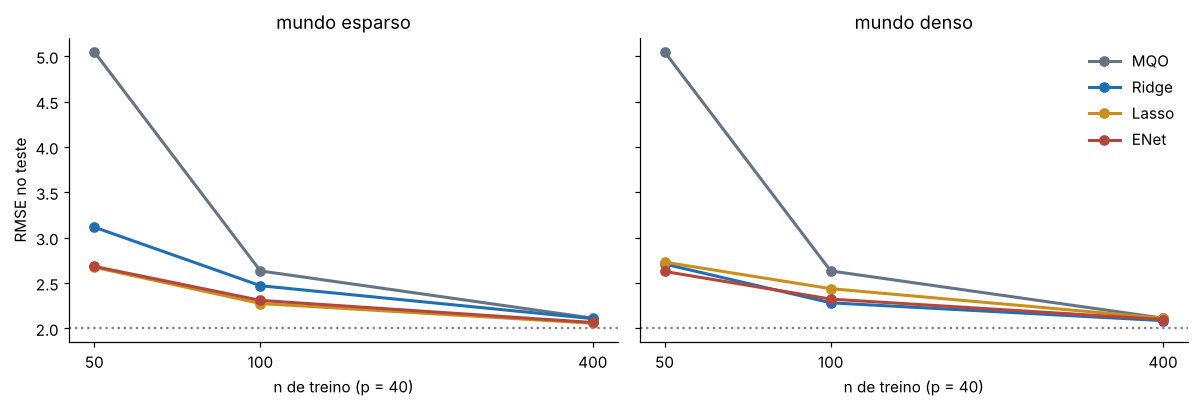

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, mundo in zip(ax, ["esparso", "denso"]):
    for nome in ["MQO", "Ridge", "Lasso", "ENet"]:
        v = tab.loc[mundo, ("rmse", nome)]
        a.plot(v.index, v.values, marker="o", lw=2, color=COR[nome], label=nome)
    a.axhline(2, ls=":", color="gray"); a.set_xscale("log"); a.minorticks_off()
    a.set_xticks([50, 100, 400]); a.set_xticklabels([50, 100, 400])
    a.set(title=f"mundo {mundo}", xlabel="n de treino (p = 40)")
ax[0].set_ylabel("RMSE no teste"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Leitura.**
- Com $n$ próximo de $p$, o MQO **explode** (variância), e qualquer penalização recupera boa parte do erro.
- No mundo esparso, o lasso ganha: descartar os 35 atributos inúteis é a hipótese certa. No mundo denso, o ridge ganha: zerar efeitos pequenos e reais custa viés.
- O elastic net fica perto do melhor dos dois nos dois mundos. É o seguro de quem não sabe em que mundo está.
- Com $n=400$ ($n/p=10$), as diferenças quase somem. **Regularização é um remédio para pouca informação por parâmetro**, não um ganho automático.

## A5. Caminhos de coeficientes

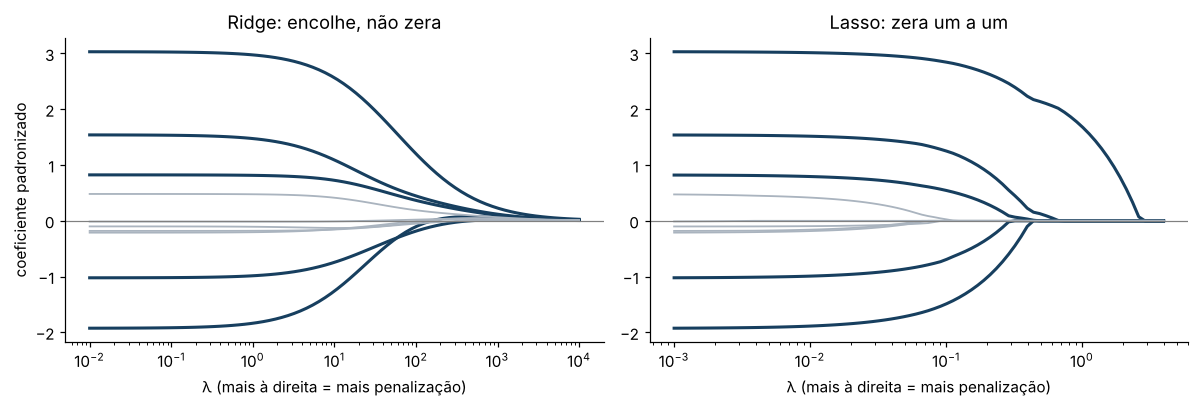

In [8]:
rng = np.random.default_rng(SEMENTE)
X, y = gera_dados(rng, 100, 10, 0.7, beta_real, 2.0)
Xs = StandardScaler().fit_transform(X)
grade_r, grade_l = np.logspace(-2, 4, 80), np.logspace(-3, 0.6, 80)
cam_r = np.array([Ridge(alpha=a).fit(Xs, y).coef_ for a in grade_r])
cam_l = np.array([Lasso(alpha=a).fit(Xs, y).coef_ for a in grade_l])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for j in range(10):
    cor, lw = ("#173F5F", 2) if beta_real[j] != 0 else ("#AAB4BF", 1.2)
    ax[0].plot(grade_r, cam_r[:, j], color=cor, lw=lw); ax[1].plot(grade_l, cam_l[:, j], color=cor, lw=lw)
for a, t in zip(ax, ["Ridge: encolhe, não zera", "Lasso: zera um a um"]):
    a.set_xscale("log"); a.axhline(0, color="gray", lw=.8); a.set(title=t, xlabel="λ (mais à direita = mais penalização)")
ax[0].set_ylabel("coeficiente padronizado"); plt.tight_layout(); plt.show()

> **Pare e responda.** No gráfico do lasso, quais atributos saem primeiro quando $\lambda$ aumenta? Algum atributo **com efeito real** sai antes de um **sem efeito**? Isso diz algo sobre usar o lasso para "descobrir" quais variáveis importam?

## A6. Remunerômetro múltiplo na RAIS

Alvo: $\ln(\text{rem})$. Atributos: idade, tempo de emprego (numéricos, padronizados) e escolaridade, sexo, raça/cor, ocupação (CBO 6 dígitos), subsetor IBGE, natureza jurídica, porte e município (categóricos, *one-hot*).

O teste é **o mesmo da aula 5**. Para imitar o tamanho típico dos projetos de vocês, treinamos com subamostras de $n$ = 300, 1.000 e 5.000 vínculos do treino. O $\lambda$ é escolhido por validação cruzada de 5 dobras **dentro** de cada subamostra, com todo o pré-processamento dentro do `Pipeline` (sem leakage de padronização).

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold

d = pd.read_parquet(ARQUIVO_BASE)
d["tempo_emprego_meses"] = d["tempo_emprego_meses"].fillna(d["tempo_emprego_meses"].median())
NUM = ["idade", "tempo_emprego_meses"]
CAT = ["escolaridade", "sexo", "raca_cor", "cbo", "subsetor_ibge", "natureza_juridica", "tamanho_estab", "municipio"]
treino, teste = d[d["particao"] == "treino"], d[d["particao"] == "teste"]
print(f"treino: {len(treino):,} | teste: {len(teste):,}")
print("categorias distintas no treino completo:", {c: treino[c].nunique() for c in CAT})

treino: 493,307 | teste: 164,436
categorias distintas no treino completo: {'escolaridade': 11, 'sexo': 2, 'raca_cor': 6, 'cbo': 1828, 'subsetor_ibge': 25, 'natureza_juridica': 49, 'tamanho_estab': 9, 'municipio': 223}


In [10]:
def preparo(min_freq=None):
    return ColumnTransformer([
        ("num", StandardScaler(), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=min_freq), CAT),
    ])

def remunerometro(n, min_freq=None):
    s = treino.sample(n, random_state=SEMENTE)
    Xtr, ytr = s[NUM + CAT], s["log_rem"].to_numpy()
    Xte, yte, rem_te = teste[NUM + CAT], teste["log_rem"].to_numpy(), teste["rem_dez"].to_numpy()
    cv = KFold(5, shuffle=True, random_state=SEMENTE)
    candidatos = {
        "MQO": Pipeline([("prep", preparo(min_freq)), ("reg", LinearRegression())]),
        "Ridge": GridSearchCV(Pipeline([("prep", preparo(min_freq)), ("reg", Ridge())]),
                              {"reg__alpha": np.logspace(-2, 3, 16)}, cv=cv, scoring="neg_root_mean_squared_error"),
        "Lasso": GridSearchCV(Pipeline([("prep", preparo(min_freq)), ("reg", Lasso(max_iter=5000))]),
                              {"reg__alpha": np.logspace(-5, -1, 13)}, cv=cv, scoring="neg_root_mean_squared_error"),
    }
    linhas = [{"n": n, "modelo": "baseline (média)", "RMSE log": rmse(yte, np.full(len(yte), ytr.mean())),
               "MAE R$": mae(rem_te, np.full(len(yte), np.exp(np.median(ytr)))), "coef. ≠ 0": 0, "λ (sklearn)": np.nan}]
    ajustados = {}
    for nome, m in candidatos.items():
        m.fit(Xtr, ytr)
        final = m.best_estimator_ if hasattr(m, "best_estimator_") else m
        pred = m.predict(Xte)
        linhas.append({"n": n, "modelo": nome, "RMSE log": rmse(yte, pred), "MAE R$": mae(rem_te, np.exp(pred)),
                       "coef. ≠ 0": int(np.sum(np.abs(final[-1].coef_) > 1e-10)),
                       "λ (sklearn)": m.best_params_["reg__alpha"] if hasattr(m, "best_params_") else np.nan})
        ajustados[nome] = final
    return pd.DataFrame(linhas), ajustados

tabelas, modelos_rais = [], {}
for n in [300, 1000, 5000]:
    t, ajustados = remunerometro(n)
    tabelas.append(t); modelos_rais[n] = ajustados
rais_reg = pd.concat(tabelas, ignore_index=True)
rais_reg

,n,modelo,RMSE log,MAE R$,coef. ≠ 0,λ (sklearn)
0,300,baseline (média),0.6598,"1,956.3093",0,NaN
1,300,MQO,0.8255,"2,570.6301",282,NaN
2,300,Ridge,0.4753,"1,491.9768",282,2.1544
3,300,Lasso,0.4917,"1,553.1442",34,0.0046
4,1000,baseline (média),0.6592,"1,955.8693",0,NaN
5,1000,MQO,0.5115,"1,506.5762",492,NaN
6,1000,Ridge,0.4317,"1,324.8868",492,2.1544
7,1000,Lasso,0.4383,"1,341.7263",105,0.0010
8,5000,baseline (média),0.6593,"1,955.8636",0,NaN
9,5000,MQO,0.4076,"1,205.7262",882,NaN


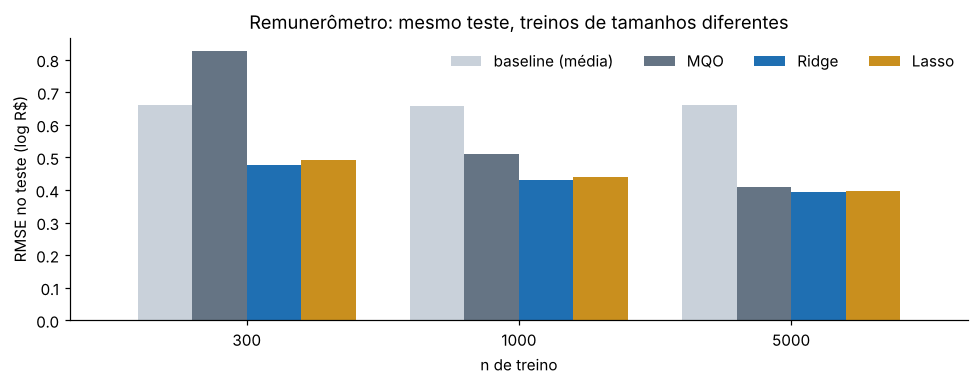

In [11]:
piv = rais_reg.pivot(index="n", columns="modelo", values="RMSE log")[["baseline (média)", "MQO", "Ridge", "Lasso"]]
ax = piv.plot.bar(figsize=(9, 3.6), color=[COR["base"], COR["MQO"], COR["Ridge"], COR["Lasso"]], width=.8, rot=0)
ax.set(ylabel="RMSE no teste (log R$)", xlabel="n de treino", title="Remunerômetro: mesmo teste, treinos de tamanhos diferentes")
ax.legend(frameon=False, ncol=4); plt.tight_layout(); plt.show()

**Leitura.**
- Com $n=300$ e centenas de colunas *one-hot*, o MQO fica **pior que o baseline**: ele ajusta exatamente categorias com um ou dois vínculos e erra em quem ele nunca viu. Ridge e lasso cortam o erro em cerca de 40%.
- Com $n=5.000$ a vantagem cai para poucos centésimos. É o mesmo padrão do experimento simulado, agora em dado real.
- O lasso entrega erro parecido com o do ridge usando uma fração dos coeficientes. Isso tem valor operacional: menos atributos para coletar e explicar.

Os coeficientes que o lasso manteve com $n=1.000$:

In [12]:
lasso_1000 = modelos_rais[1000]["Lasso"]
nomes = lasso_1000.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lasso_1000[-1].coef_, index=nomes)
mantidos = coefs[coefs != 0].sort_values()
print(f"{len(mantidos)} de {len(coefs)} coeficientes não nulos")
pd.concat([mantidos.head(8), mantidos.tail(8)]).to_frame("coef. (log R$)")

105 de 492 coeficientes não nulos


,coef. (log R$)
cat__natureza_juridica_1031,-0.4012
cat__natureza_juridica_1244,-0.3624
cat__cbo_111415,-0.3399
cat__cbo_717020,-0.2999
cat__cbo_515110,-0.2381
cat__natureza_juridica_2135,-0.2059
cat__cbo_514215,-0.1811
cat__cbo_514320,-0.1768
cat__natureza_juridica_2011,0.5595
cat__escolaridade_Doutorado,0.5620


> **Cuidado de interpretação.** Os coeficientes penalizados são **viesados em direção a zero** e não têm erro-padrão clássico. A seleção do lasso é instável entre amostras quando há atributos correlacionados (CBO, subsetor e natureza jurídica contam histórias parecidas). Use o lasso para **prever** e **simplificar**, não para afirmar quais fatores "determinam" o salário.

**Uma regularização manual.** O `OneHotEncoder(min_frequency=k)` junta categorias com menos de $k$ vínculos em "outras". Isso também reduz a variância. Rode a célula abaixo e compare com a tabela acima.

In [13]:
t_agrupado, _ = remunerometro(1000, min_freq=5)
t_agrupado.assign(codificacao="min_frequency=5")

,n,modelo,RMSE log,MAE R$,coef. ≠ 0,λ (sklearn),codificacao
0,1000,baseline (média),0.6592,"1,955.8693",0,NaN,min_frequency=5
1,1000,MQO,0.4452,"1,368.9808",142,NaN,min_frequency=5
2,1000,Ridge,0.4410,"1,371.1131",142,2.1544,min_frequency=5
3,1000,Lasso,0.4423,"1,364.4071",111,0.0005,min_frequency=5


# Parte B — Classificação: quando o alvo é sim/não

| | Regressão | Classificação |
|---|---|---|
| alvo $y$ | número (R$, dias, toneladas) | categoria (sim/não; A/B/C) |
| o modelo entrega | $\hat y=\hat E(y\mid x)$ | $\hat p(x)=\hat P(y=1\mid x)$ e uma classe |
| perda típica | quadrática, absoluta | log-loss para estimar; custo dos erros para decidir |
| decisão | usar o valor previsto | agir se $\hat p(x)\ge t$, com $t$ escolhido pelo custo |

## B1. Logística à mão: casa própria e renda (dados de brinquedo)

$$P(y=1\mid x)=\sigma(\beta_0+\beta_1x)=\frac{1}{1+e^{-(\beta_0+\beta_1x)}},\qquad
\ln\frac{p}{1-p}=\beta_0+\beta_1x .$$

Estimação por máxima verossimilhança: maximizar $\ell(\boldsymbol\beta)=\sum_i\big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\big]$. Não há forma fechada; usa-se Newton–Raphson (IRLS). A derivação completa fica para a próxima aula de classificação.

In [14]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

casa = pd.DataFrame({"familia": range(1, 11),
                     "renda": [8, 16, 18, 11, 12, 19, 20, 13, 9, 10],     # R$ mil
                     "casa_propria": [0, 0, 1, 0, 0, 1, 1, 1, 0, 0]})
logit_casa = smf.logit("casa_propria ~ renda", data=casa).fit(disp=0)
b0, b1 = logit_casa.params
print(logit_casa.summary2().tables[1].round(3))
print(f"\nrazão de chances por R$ 1 mil: e^β1 = {np.exp(b1):.3f}  ->  chances multiplicadas por {np.exp(b1):.2f}")
print(f"P(casa | renda = 15) = {logit_casa.predict(pd.DataFrame({'renda': [15]}))[0]:.3f}")
print(f"renda em que p = 0,5: -β0/β1 = {-b0 / b1:.2f} mil")
print(f"efeito marginal em renda = 15: p(1-p)β1 = {(lambda p: p*(1-p)*b1)(logit_casa.predict(pd.DataFrame({'renda':[15]}))[0]):.3f} por R$ 1 mil")
casa["p_hat"] = logit_casa.predict(casa).round(3)
casa["classe (t = 0,5)"] = (casa["p_hat"] >= 0.5).astype(int)
casa

            Coef.  Std.Err.       z  P>|z|   [0.025  0.975]
Intercept -9.0890    4.9320 -1.8430 0.0650 -18.7560  0.5770
renda      0.6120    0.3340  1.8300 0.0670  -0.0430  1.2680

razão de chances por R$ 1 mil: e^β1 = 1.845  ->  chances multiplicadas por 1.84
P(casa | renda = 15) = 0.524
renda em que p = 0,5: -β0/β1 = 14.85 mil
efeito marginal em renda = 15: p(1-p)β1 = 0.153 por R$ 1 mil


,familia,renda,casa_propria,p_hat,"classe (t = 0,5)"
0,1,8,0,0.0150,0
1,2,16,0,0.6700,1
2,3,18,1,0.8730,1
3,4,11,0,0.0870,0
4,5,12,0,0.1490,0
5,6,19,1,0.9270,1
6,7,20,1,0.9590,1
7,8,13,1,0.2440,0
8,9,9,0,0.0270,0
9,10,10,0,0.0490,0


In [15]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(casa["casa_propria"], casa["classe (t = 0,5)"])
pd.DataFrame(cm, index=["real 0", "real 1"], columns=["previsto 0", "previsto 1"])

,previsto 0,previsto 1
real 0,5,1
real 1,1,3


> **Calcule à mão.** Com a matriz acima: acurácia, *precision* (dos que o modelo disse "sim", quantos são?), *recall* (dos que são "sim", quantos o modelo achou?) e especificidade.

### Separação perfeita: quando a máxima verossimilhança não existe

Troque duas famílias de lado (renda 16 → sim; renda 13 → não). Agora **todas** as rendas ≥ 16 têm casa e todas ≤ 13 não têm: os dados são perfeitamente separáveis. A verossimilhança cresce sem limite quando $\beta_1\to\infty$, e o estimador não existe.

O `LogisticRegression` do `scikit-learn` não "quebra" porque, **por padrão, é penalizado com L2** (`C = 1/λ = 1`): é uma regressão logística **ridge**. Repare o que acontece quando reduzimos a penalização (aumentamos `C`).

In [16]:
from sklearn.linear_model import LogisticRegression
y_sep = np.array([0, 1, 1, 0, 0, 1, 1, 0, 0, 0])
Xr = casa[["renda"]].to_numpy(float)
pd.DataFrame([{"C (= 1/λ)": C, "β0": m.intercept_[0], "β1": m.coef_[0, 0]}
              for C in [1, 100, 10_000, 1_000_000]
              for m in [LogisticRegression(C=C, max_iter=100_000).fit(Xr, y_sep)]]).round(2)

,C (= 1/λ),β0,β1
0,1,-14.9900,1.0200
1,100,-44.3700,3.0600
2,10000,-81.1700,5.6100
3,1000000,-82.7100,5.7200


**Leitura.** Sem freio, $\hat\beta_1$ cresce indefinidamente. A penalização ridge que vimos na Parte A é exatamente o que torna a logística estimável aqui. Moral prática: ao usar `scikit-learn`, saiba que `C` é um hiperparâmetro e que o padrão **não** é a logística "pura" dos livros de econometria.

## B2. RAIS: o vínculo paga mais de 2 salários mínimos?

Alvo: $y=1$ se a remuneração de dezembro supera $2\times$ R\$ 1.518 = R\$ 3.036.

**Uso ilustrativo para a decisão.** Uma instituição financeira quer pré-aprovar um limite maior de crédito para quem tem remuneração acima de 2 SM, usando só atributos cadastrais (sem consultar o salário). Cada acerto positivo rende $B=1$; cada falso positivo (aprovar quem não tem a renda) custa $C=3$. A regra de 10/09 diz: aprovar se $\hat p\ge t^*=C/(B+C)=0{,}75$.

In [17]:
d["acima2sm"] = (d["rem_dez"] > 2 * SALARIO_MINIMO_2025).astype(int)
d["tempo_emprego_anos"] = d["tempo_emprego_meses"] / 12
d["mulher"] = (d["sexo"] == "2").astype(int)
treino, teste = d[d["particao"] == "treino"], d[d["particao"] == "teste"]
amostra = treino.sample(20_000, random_state=SEMENTE)
print("proporção de y = 1  | treino:", round(treino["acima2sm"].mean(), 3), "| teste:", round(teste["acima2sm"].mean(), 3))
print("baseline de classe majoritária (sempre 0): acurácia =", round(1 - teste["acima2sm"].mean(), 3))

proporção de y = 1  | treino: 0.322 | teste: 0.323
baseline de classe majoritária (sempre 0): acurácia = 0.677


### Por que não uma regressão linear no 0/1 (modelo de probabilidade linear)?

In [18]:
formula = "acima2sm ~ anos_estudo + idade + I(idade**2) + mulher + tempo_emprego_anos"
mpl = smf.ols(formula, data=amostra).fit()
p_mpl = mpl.predict(teste)
print(f"MPL: {((p_mpl < 0) | (p_mpl > 1)).mean():.1%} das 'probabilidades' no teste estão fora de [0, 1] "
      f"(mín. {p_mpl.min():.2f}, máx. {p_mpl.max():.2f})")

MPL: 5.9% das 'probabilidades' no teste estão fora de [0, 1] (mín. -0.60, máx. 1.25)


### Logit com poucos atributos: leitura dos coeficientes

In [19]:
logit = smf.logit(formula, data=amostra).fit(disp=0)
leitura = pd.DataFrame({"β (log-odds)": logit.params, "e^β (razão de chances)": np.exp(logit.params),
                        "p-valor": logit.pvalues})
efeitos = logit.get_margeff(at="overall").summary_frame()["dy/dx"].rename("efeito marginal médio (p.p./100)")
leitura.join(efeitos).round(4)

,β (log-odds),e^β (razão de chances),p-valor,efeito marginal médio (p.p./100)
Intercept,-9.8198,0.0001,0.0000,NaN
anos_estudo,0.3299,1.3909,0.0000,0.0532
idade,0.2027,1.2246,0.0000,0.0327
I(idade ** 2),-0.0022,0.9978,0.0000,-0.0004
mulher,-0.1078,0.8978,0.0029,-0.0174
tempo_emprego_anos,0.0735,1.0763,0.0000,0.0119


**Como ler cada coluna** (sem linguagem causal):
- $\beta$: diferença no **log das chances** por unidade do atributo, mantidos os demais;
- $e^{\beta}$: as chances são **multiplicadas** por esse fator. Ex.: um ano a mais de estudo está associado a chances ≈ 1,39 vez maiores (≈ +39%). Não é "+39 pontos percentuais" na probabilidade;
- efeito marginal médio $\overline{p_i(1-p_i)}\,\beta_j$: variação média da **probabilidade**. É a medida que um gestor entende.

### Pipeline completo e avaliação no teste

In [20]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, ConfusionMatrixDisplay)
NUM_C = ["idade", "tempo_emprego_anos"]
clf = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), NUM_C),
                                ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT)])),
    ("logit", LogisticRegression(C=1.0, max_iter=2000)),     # L2 por padrão
]).fit(amostra[NUM_C + CAT], amostra["acima2sm"])

y_te = teste["acima2sm"].to_numpy()
p_te = clf.predict_proba(teste[NUM_C + CAT])[:, 1]
p_simples = logit.predict(teste).to_numpy()

def metricas(y, p, t):
    yh = (p >= t).astype(int)
    return {"limiar": t, "acurácia": accuracy_score(y, yh), "precision": precision_score(y, yh),
            "recall": recall_score(y, yh), "F1": f1_score(y, yh)}
pd.DataFrame([{"modelo": nome, "AUC": roc_auc_score(y_te, p), "log-loss": log_loss(y_te, p), **metricas(y_te, p, t)}
              for nome, p in [("logit 5 atributos", p_simples), ("logit completo (L2)", p_te)]
              for t in [0.5, 0.75]]).round(3)

,modelo,AUC,log-loss,limiar,acurácia,precision,recall,F1
0,logit 5 atributos,0.7950,0.5050,0.5000,0.7730,0.7040,0.5160,0.5950
1,logit 5 atributos,0.7950,0.5050,0.7500,0.7290,0.8650,0.1920,0.3140
2,logit completo (L2),0.9240,0.3220,0.5000,0.8620,0.8170,0.7400,0.7770
3,logit completo (L2),0.9240,0.3220,0.7500,0.8340,0.9120,0.5370,0.6760


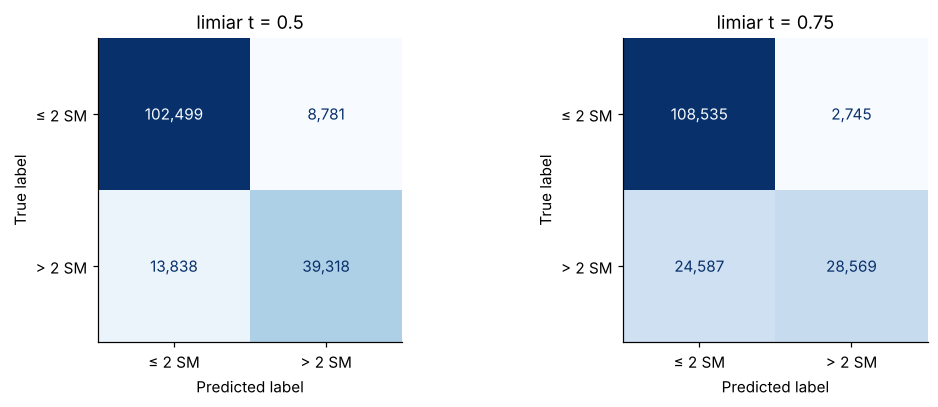

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, t in zip(ax, [0.5, 0.75]):
    ConfusionMatrixDisplay.from_predictions(y_te, (p_te >= t).astype(int), ax=a, colorbar=False, cmap="Blues",
                                            display_labels=["≤ 2 SM", "> 2 SM"], values_format=",")
    a.set_title(f"limiar t = {t}")
plt.tight_layout(); plt.show()

### Escolhendo o limiar pelo custo, não pelo hábito

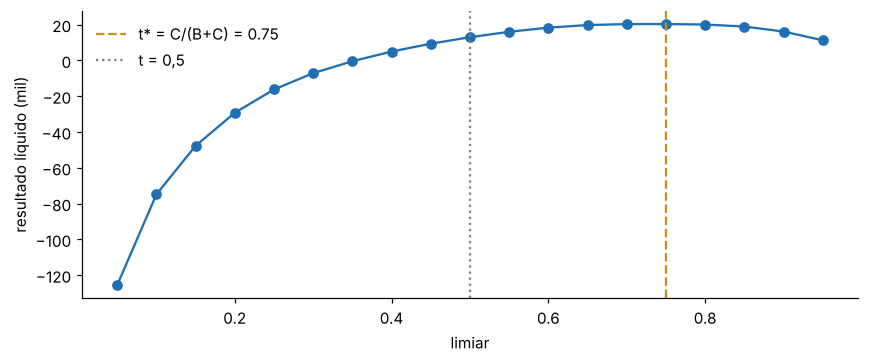

limiar com maior resultado no teste: 0.75 | regra teórica: 0.75


In [22]:
B, Cfp = 1, 3
grade_t = np.round(np.arange(0.05, 0.96, 0.05), 2)
resultado = [(t, B * np.sum((p_te >= t) & (y_te == 1)) - Cfp * np.sum((p_te >= t) & (y_te == 0))) for t in grade_t]
res_t = pd.DataFrame(resultado, columns=["limiar", "resultado líquido"])
t_emp = res_t.loc[res_t["resultado líquido"].idxmax(), "limiar"]

plt.figure(figsize=(8, 3.4))
plt.plot(res_t["limiar"], res_t["resultado líquido"] / 1000, marker="o", color=COR["Ridge"])
plt.axvline(Cfp / (B + Cfp), color=COR["Lasso"], ls="--", label=f"t* = C/(B+C) = {Cfp/(B+Cfp):.2f}")
plt.axvline(0.5, color="gray", ls=":", label="t = 0,5")
plt.xlabel("limiar"); plt.ylabel("resultado líquido (mil)"); plt.legend(frameon=False); plt.tight_layout(); plt.show()
print(f"limiar com maior resultado no teste: {t_emp} | regra teórica: {Cfp/(B+Cfp):.2f}")

**Leitura.** O limiar 0,5 maximiza a acurácia apenas quando os dois erros custam o mesmo. Com falso positivo três vezes mais caro, o ótimo empírico fica perto de $t^*=0{,}75$, **desde que as probabilidades estejam bem calibradas**. Calibração, curva ROC e desbalanceamento voltam na próxima aula de classificação.

> **Atenção metodológica.** Aqui o limiar foi varrido no **teste** só para mostrar a coincidência com a teoria. No projeto, o limiar se escolhe na validação (ou por validação cruzada) e o teste é aberto uma única vez.

---

# Para entregar (individual) — junto com a Ficha do Modelo 2

1. **À mão (A1 e A3).** Refaça o ridge 2×2 com $\lambda=2$ e o limiar suave com $\lambda=0{,}6$. Mostre as contas.
2. **Escala.** Rode A6 **sem** o `StandardScaler` nos numéricos e com `tempo_emprego_meses` multiplicado por 1.000. O que acontece com o coeficiente desse atributo no lasso? Por quê?
3. **Seleção instável.** Repita o lasso de A6 ($n=1.000$) com três sementes diferentes. Quantos atributos mantidos são comuns às três? O que isso implica para interpretar a seleção?
4. **Projeto.** No dado da sua equipe: calcule $n$ de treino e $p$ após o *one-hot*. Ajuste MQO, ridge e lasso no mesmo `Pipeline`, com $\lambda$ por validação cruzada, e reporte a tabela baseline × MQO × ridge × lasso no teste congelado.
5. **Classificação.** Escreva uma frase de interpretação para `mulher` usando (a) a razão de chances e (b) o efeito marginal médio. Qual das duas você levaria a um gestor?
6. **Decisão.** Refaça a curva de limiar com $B=2$ e $C=1$. Qual o novo $t^*$? Por que o recall sobe?

*Aprofundamento opcional (Estatística):* mostre que, com $\mathbf X=\mathbf U\mathbf D\mathbf V^\top$ (SVD), $\mathbf X\hat{\boldsymbol\beta}^{\text{ridge}}=\sum_j \mathbf u_j\frac{d_j^2}{d_j^2+\lambda}\mathbf u_j^\top\mathbf y$, e interprete o fator $d_j^2/(d_j^2+\lambda)$. Verifique numericamente com os dados de A2.